# Rain Prediction — XGBoost

Gradient-boosted tree pipeline for predicting next-day rainfall (`RainTomorrow`) on the
MICE-preprocessed WeatherAUS dataset. This notebook mirrors the structure of
`LogisticRegression.ipynb` so the two models are compared on identical data, splits,
cross-validation, threshold logic, calibration machinery, and metrics — every difference
is then attributable to the hypothesis class.

See [`methodology_XGBoost.md`](./methodology_XGBoost.md) for the full design rationale.

Numerical outputs are mirrored to `XGB_result.txt`; every figure is saved as a PNG under
`figures/`. Designed to run on **Google Colab** — it self-installs packages, auto-discovers
the input CSV, and bundles the artifacts into a downloadable zip at the end.


## 1. Colab setup, imports and constants

In [1]:
# --- Colab environment setup ---
# Detect Colab; install/upgrade XGBoost + SHAP; show the attached GPU.
import subprocess, sys as _sys
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    # -U ensures XGBoost >= 2.0 (needed for the `device="cuda"` API).
    subprocess.run([_sys.executable, '-m', 'pip', '-q', 'install', '-U', 'xgboost', 'shap'],
                   check=False)
    # Show the attached accelerator (T4 / L4 / A100).
    subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total,driver_version',
                    '--format=csv,noheader'], check=False)
    # The Drive mount itself happens in the data-loading cell below.

print(f'Running on Colab: {IN_COLAB}')

Running on Colab: True


In [2]:
import os
import sys
import zipfile
import warnings
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    RandomizedSearchCV, TimeSeriesSplit, learning_curve,
)
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    f1_score, precision_score, recall_score,
    roc_curve, roc_auc_score, precision_recall_curve, auc,
    brier_score_loss, log_loss,
)
from sklearn.calibration import calibration_curve, CalibratedClassifierCV

import xgboost as xgb
from xgboost import XGBClassifier

# When the model lives on GPU but the input frame is on host, XGBoost warns on every
# predict. It is harmless here; silence it to keep the log readable.
warnings.filterwarnings('ignore', category=UserWarning, module='xgboost')

# Optional dependencies — degrade gracefully if missing.
try:
    import shap
    HAS_SHAP = True
except ImportError:
    HAS_SHAP = False

try:
    from imblearn.over_sampling import SMOTE
    HAS_SMOTE = True
except ImportError:
    HAS_SMOTE = False

RANDOM_STATE = 42
TEST_CUTOFF = pd.Timestamp('2016-01-01')   # train < cutoff <= test

# --- GPU configuration ---------------------------------------------------------
def _gpu_available():
    """Probe for a usable CUDA device by training a 1-round model on it."""
    try:
        dtest = xgb.DMatrix(np.zeros((8, 2)), label=np.zeros(8))
        xgb.train({'device': 'cuda', 'tree_method': 'hist'}, dtest, num_boost_round=1)
        return True
    except Exception as e:
        print(f'CUDA probe failed ({type(e).__name__}); falling back to CPU.')
        return False

USE_GPU = _gpu_available()
DEVICE = 'cuda' if USE_GPU else 'cpu'
# A single GPU cannot be shared across parallel CV workers without contention/OOM,
# so on GPU we run CV folds sequentially (each fit still uses the GPU). On CPU we
# fan out across cores instead.
SEARCH_N_JOBS = 1 if USE_GPU else -1

XGB_KW = dict(
    tree_method='hist',
    device=DEVICE,
    eval_metric='logloss',
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

def make_xgb(**overrides):
    """XGBClassifier carrying the shared device/seed config; overrides win."""
    params = dict(XGB_KW)
    params.update(overrides)
    return XGBClassifier(**params)

print(f'xgboost {xgb.__version__} | device: {DEVICE} | search n_jobs: {SEARCH_N_JOBS}')
print(f'shap: {HAS_SHAP} | imblearn(SMOTE): {HAS_SMOTE}')

xgboost 3.2.0 | device: cuda | search n_jobs: 1
shap: True | imblearn(SMOTE): True


### Output setup

A `figures/` directory and an `XGB_result.txt` file are created next to this notebook.
`sys.stdout` is teed so every `print(...)` is mirrored to the results file. Each plot is
saved with `save_fig(...)` before `plt.show()`.

In [3]:
# Create output locations
os.makedirs('figures', exist_ok=True)

_XGB_RESULT_PATH = 'XGB_result.txt'
_XGB_RESULT_FILE = open(_XGB_RESULT_PATH, 'w', encoding='utf-8')

class _Tee:
    """Write to both real stdout and the results file."""
    def __init__(self, *streams):
        self._streams = streams
    def write(self, data):
        for s in self._streams:
            s.write(data)
    def flush(self):
        for s in self._streams:
            s.flush()
    def isatty(self):
        return False

_ORIG_STDOUT = sys.stdout
sys.stdout = _Tee(_ORIG_STDOUT, _XGB_RESULT_FILE)

print('# XGBoost — numerical outputs')
print(f'# Generated: {datetime.now().strftime("%Y-%m-%d %H:%M:%S")}')

def log_section(title):
    """Print a section banner so XGB_result.txt is easy to skim."""
    bar = '=' * 72
    print(f'\n{bar}\n{title}\n{bar}')

def save_fig(name, fig=None):
    """Save the current (or given) figure to figures/<name>.png at 150 dpi."""
    if fig is None:
        fig = plt.gcf()
    path = f'figures/{name}.png'
    fig.savefig(path, dpi=150, bbox_inches='tight')
    print(f'  [saved {path}]')

# XGBoost — numerical outputs
# Generated: 2026-06-15 05:07:07


## 2. Data loading

In [ ]:
log_section('2. Data loading')

# Sur Colab : monter le Drive. En local : lire ../../data/, alimenté par
# 3.preprocessing_trend_group.ipynb et 4_preprocessing_imputation.ipynb.
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = "/content/drive/MyDrive/Colab_Notebooks"
else:
    DATA_DIR = "../../data"

DATA_PATH = f"{DATA_DIR}/weatherAUS_MICE_cyclic.csv"

df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()
df['Date'] = pd.to_datetime(df['Date'])
print(f'Loaded {df.shape[0]:,} rows x {df.shape[1]} columns from {DATA_PATH}')
print(f'Date range: {df["Date"].min().date()} to {df["Date"].max().date()}')
print(f'Locations : {df["Location"].nunique()}')
df['RainTomorrow'] = df['RainTomorrow'].astype(bool)

## 3. Feature engineering

Identical drop list and 23-feature matrix as the logistic-regression study, for
comparability. **No `StandardScaler`** is applied — gradient-boosted trees are
scale-invariant, so standardization is inert and would only obscure SHAP units.

In [5]:
if 'Date_sin' not in df.columns:
    day_of_year = df['Date'].dt.dayofyear
    df['Date_sin'] = np.sin(2 * np.pi * day_of_year / 365.25)
    df['Date_cos'] = np.cos(2 * np.pi * day_of_year / 365.25)

In [6]:
log_section('3. Feature engineering')

DROP_COLS = [
    'Date',
    'Location',                              # no per-station dummies
    'WindGustDir', 'WindDir9am', 'WindDir3pm',  # discrete labels; sin/cos retained
    'RainToday',                             # near-leakage; the model receives the rest of today
    'RainTomorrow',                          # target
    'Humidity9am',                           # keep Humidity3pm (the stronger predictor)
    'Month', 'weather_trend_group', 'Sunshine_trend_group',
]

X_full = df.drop(columns=[c for c in DROP_COLS if c in df.columns]).copy()
y_full = df['RainTomorrow']

# Coerce any residual non-numeric columns; we keep only numeric features.
X_full = X_full.select_dtypes(include=[np.number])

print(f'Feature matrix: {X_full.shape}')
print(f'Columns ({len(X_full.columns)}):')
for c in X_full.columns:
    print(f'  - {c}')
print(f'\nClass distribution (RainTomorrow):')
print(y_full.value_counts().to_string())
print(f'Rain proportion: {y_full.mean():.4f}')

## 4. Chronological train/test split

Rows sorted by date and partitioned at `2016-01-01`, reproducing the LR split exactly.
No scaler is fit — the raw feature frame is fed directly to XGBoost.

In [7]:
log_section('4. Chronological train/test split')

df_sorted = df.sort_values('Date').reset_index(drop=True)
X_sorted = X_full.loc[df_sorted.index].reset_index(drop=True)
y_sorted = y_full.loc[df_sorted.index].reset_index(drop=True)
dates_sorted = df_sorted['Date']

train_mask = dates_sorted < TEST_CUTOFF
X_train = X_sorted[train_mask].reset_index(drop=True)
X_test  = X_sorted[~train_mask].reset_index(drop=True)
y_train = y_sorted[train_mask].reset_index(drop=True)
y_test  = y_sorted[~train_mask].reset_index(drop=True)

# XGBoost wants integer labels.
y_train_i = y_train.astype(int)
y_test_i  = y_test.astype(int)

print(f'Train: {X_train.shape[0]:,} rows | dates {dates_sorted[train_mask].min().date()} to {dates_sorted[train_mask].max().date()}')
print(f'Test : {X_test.shape[0]:,} rows | dates {dates_sorted[~train_mask].min().date()} to {dates_sorted[~train_mask].max().date()}')
print(f'Train rain proportion: {y_train.mean():.4%}')
print(f'Test  rain proportion: {y_test.mean():.4%}')
print(f'Drift (test - train) : {(y_test.mean() - y_train.mean()) * 100:+.2f} percentage points')

# Inverse class ratio used for scale_pos_weight downstream.
pos_rate = float(y_train.mean())
SPW = (1 - pos_rate) / pos_rate
print(f'scale_pos_weight (neg/pos) = {SPW:.4f}')

ts_cv = TimeSeriesSplit(n_splits=5)

## 5. Baseline model

Untuned `XGBClassifier` with library defaults, no imbalance reweighting, evaluated at the
default 0.5 threshold. Establishes the tree-ensemble floor (LR baseline F1 was 0.61).

In [8]:
log_section('5. Baseline model')

baseline = make_xgb()
baseline.fit(X_train, y_train_i)

y_pred_baseline = baseline.predict(X_test)
y_proba_baseline = baseline.predict_proba(X_test)[:, 1]

print('Baseline classification report:')
print(classification_report(y_test_i, y_pred_baseline))
print(f'ROC-AUC: {roc_auc_score(y_test_i, y_proba_baseline):.4f}')

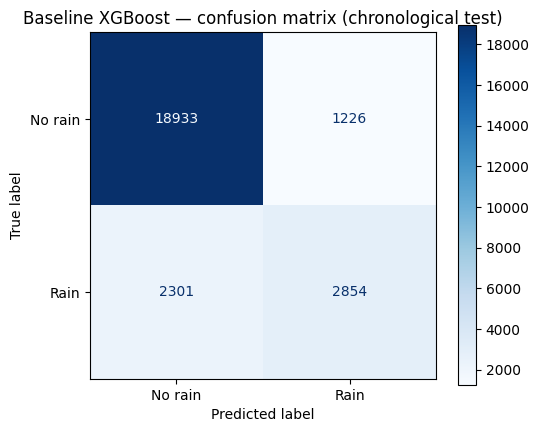

In [10]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
cm = confusion_matrix(y_test_i, y_pred_baseline)
ConfusionMatrixDisplay(cm, display_labels=['No rain', 'Rain']).plot(cmap='Blues', ax=ax)
ax.set_title('Baseline XGBoost — confusion matrix (chronological test)')
plt.tight_layout()
save_fig('01_baseline_confusion_matrix', fig)
plt.show()

## 6. Hyperparameter tuning with TimeSeriesSplit

`RandomizedSearchCV` over the XGBoost grid, scored on rain-class F1, with
`TimeSeriesSplit(5)` folds. `scale_pos_weight` is searched jointly with the tree
hyperparameters. Random (not exhaustive) search because the grid is ~100k configurations.

In [11]:
log_section('6. Hyperparameter tuning')

param_dist = {
    'n_estimators':     [200, 400, 600, 800],
    'max_depth':        [3, 4, 5, 6, 8],
    'learning_rate':    [0.01, 0.03, 0.05, 0.1],
    'subsample':        [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'min_child_weight': [1, 3, 5],
    'gamma':            [0, 0.1, 0.5],
    'reg_lambda':       [1, 5, 10],
    'scale_pos_weight': [1, SPW],
}

N_ITER = 30
xgb_base = make_xgb()

search = RandomizedSearchCV(
    xgb_base, param_dist,
    n_iter=N_ITER,
    scoring='f1',
    cv=ts_cv,
    n_jobs=SEARCH_N_JOBS,   # 1 on GPU (sequential folds), -1 on CPU
    random_state=RANDOM_STATE,
    verbose=1,
)
search.fit(X_train, y_train_i)

best_model = search.best_estimator_
best_params = search.best_params_
print(f'Best params : {best_params}')
print(f'Best CV F1  : {search.best_score_:.4f}')

In [12]:
y_pred_tuned = best_model.predict(X_test)
y_proba_tuned = best_model.predict_proba(X_test)[:, 1]

print('Tuned model — classification report (threshold 0.5):')
print(classification_report(y_test_i, y_pred_tuned))
print(f'ROC-AUC: {roc_auc_score(y_test_i, y_proba_tuned):.4f}')

## 7. Class imbalance — strategies

Three handlings compared at a fixed reference configuration so the F1 deltas are
attributable to the imbalance mechanism: default (`scale_pos_weight=1`),
`scale_pos_weight=(1-p)/p`, and SMOTE (run only if `imbalanced-learn` is installed).

In [13]:
log_section('7. Class imbalance — strategies')

REF_PARAMS = dict(
    n_estimators=400, max_depth=5, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8,
)

# 1) default (no reweighting)
m1 = make_xgb(scale_pos_weight=1, **REF_PARAMS).fit(X_train, y_train_i)
p1 = m1.predict(X_test)

# 2) scale_pos_weight = neg/pos
m2 = make_xgb(scale_pos_weight=SPW, **REF_PARAMS).fit(X_train, y_train_i)
p2 = m2.predict(X_test)

rows = [
    {'config': 'default', 'F1': f1_score(y_test_i, p1),
     'precision': precision_score(y_test_i, p1), 'recall': recall_score(y_test_i, p1)},
    {'config': 'scale_pos_weight', 'F1': f1_score(y_test_i, p2),
     'precision': precision_score(y_test_i, p2), 'recall': recall_score(y_test_i, p2)},
]

# 3) SMOTE (optional)
m3 = p3 = None
if HAS_SMOTE:
    sm = SMOTE(random_state=RANDOM_STATE)
    X_sm, y_sm = sm.fit_resample(X_train, y_train_i)
    print(f'SMOTE training set: {X_sm.shape[0]:,} rows ({y_sm.mean():.0%} rain)')
    m3 = make_xgb(scale_pos_weight=1, **REF_PARAMS).fit(X_sm, y_sm)
    p3 = m3.predict(X_test)
    rows.append({'config': 'SMOTE', 'F1': f1_score(y_test_i, p3),
                 'precision': precision_score(y_test_i, p3), 'recall': recall_score(y_test_i, p3)})
else:
    print('SMOTE skipped (imbalanced-learn not installed).')

imb_df = pd.DataFrame(rows).round(3)
print('\nImbalance comparison:')
print(imb_df.to_string(index=False))

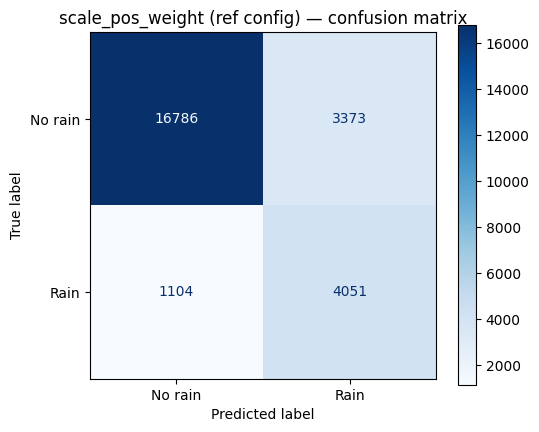

In [14]:
# Confusion matrix — scale_pos_weight
fig, ax = plt.subplots(figsize=(5.5, 4.5))
cm = confusion_matrix(y_test_i, p2)
ConfusionMatrixDisplay(cm, display_labels=['No rain', 'Rain']).plot(cmap='Blues', ax=ax)
ax.set_title('scale_pos_weight (ref config) — confusion matrix')
plt.tight_layout()
save_fig('02_scale_pos_weight_confusion_matrix', fig)
plt.show()

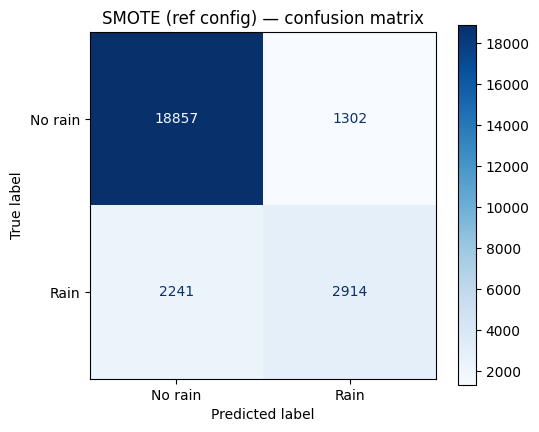

In [15]:
# Confusion matrix — SMOTE
if m3 is not None and p3 is not None:
    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    cm = confusion_matrix(y_test_i, p3)
    ConfusionMatrixDisplay(cm, display_labels=['No rain', 'Rain']).plot(cmap='Blues', ax=ax)
    ax.set_title('SMOTE (ref config) — confusion matrix')
    plt.tight_layout()
    save_fig('03_smote_confusion_matrix', fig)
    plt.show()
else:
    print('SMOTE confusion matrix skipped (imblearn unavailable).')

## 8. Threshold selection on training folds (TimeSeriesSplit)

PR-crossover criterion $D(t)=|P-F_1|+|F_1-R|$, minimized over `TimeSeriesSplit` validation
folds. The grid is **re-derived over [0.10, 0.80]** rather than inherited from the LR study,
whose narrow [0.60, 0.80] range was a consequence of `class_weight='balanced'` probability
inflation. The crossover is located empirically for the tree.

In [16]:
log_section('8. Threshold selection (TimeSeriesSplit CV)')

thresholds = np.round(np.arange(0.10, 0.81, 0.01), 2)

fold_records = []
for tr_idx, val_idx in ts_cv.split(X_train):
    fm = XGBClassifier(**best_model.get_params())
    fm.fit(X_train.iloc[tr_idx], y_train_i.iloc[tr_idx])
    fold_records.append((
        y_train_i.iloc[val_idx].values,
        fm.predict_proba(X_train.iloc[val_idx])[:, 1],
    ))

rows = []
for t in thresholds:
    f1s = [f1_score(yt, yp >= t) for yt, yp in fold_records]
    precs = [precision_score(yt, yp >= t, zero_division=0) for yt, yp in fold_records]
    recs = [recall_score(yt, yp >= t) for yt, yp in fold_records]
    rows.append({'threshold': t, 'CV_F1_mean': np.mean(f1s), 'CV_F1_std': np.std(f1s),
                 'CV_precision': np.mean(precs), 'CV_recall': np.mean(recs)})
thresh_df = pd.DataFrame(rows)

In [17]:
thresh_df['diff'] = abs(thresh_df['CV_precision'] - thresh_df['CV_F1_mean']) + abs(thresh_df['CV_F1_mean'] - thresh_df['CV_recall'])

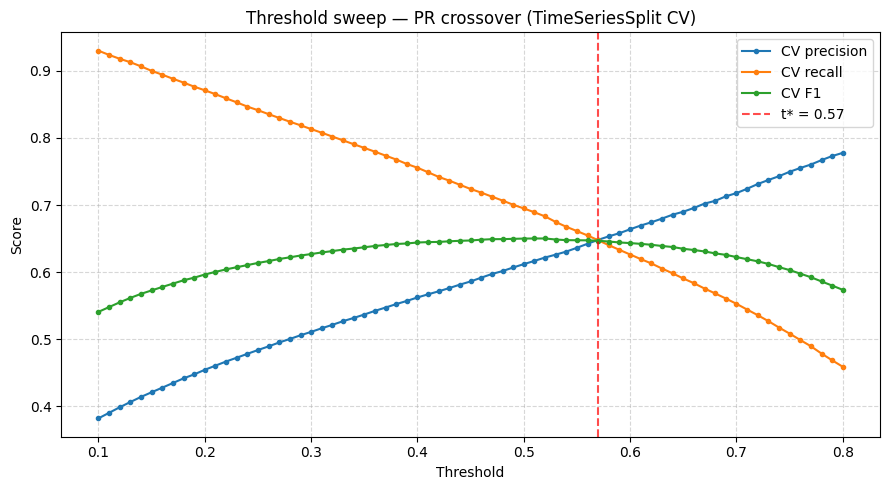

In [18]:
best_threshold = float(thresh_df.loc[thresh_df['diff'].idxmin(), 'threshold'])
print(f'CV-selected threshold: {best_threshold}')
print('\nThreshold sweep table (every 5th row):')
print(thresh_df.iloc[::5].to_string(index=False, float_format='%.4f'))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(thresh_df['threshold'], thresh_df['CV_precision'], 'o-', label='CV precision', ms=3)
ax.plot(thresh_df['threshold'], thresh_df['CV_recall'], 'o-', label='CV recall', ms=3)
ax.plot(thresh_df['threshold'], thresh_df['CV_F1_mean'], 'o-', label='CV F1', ms=3)
ax.axvline(best_threshold, color='red', linestyle='--', alpha=0.7, label=f't* = {best_threshold}')
ax.set_xlabel('Threshold'); ax.set_ylabel('Score')
ax.set_title('Threshold sweep — PR crossover (TimeSeriesSplit CV)')
ax.legend(); ax.grid(linestyle='--', alpha=0.5)
plt.tight_layout()
save_fig('04_threshold_sweep', fig)
plt.show()

# Test evaluation at t*
y_pred_thr = (y_proba_tuned >= best_threshold).astype(int)
print(f'\nTest evaluation at threshold {best_threshold}:')
print(classification_report(y_test_i, y_pred_thr))

## 9. Feature importance & SHAP attribution

Trees have no signed coefficients, so the LR bootstrap-CI analysis is replaced by
gain-based importance and SHAP values [Lundberg & Lee, 2017]. SHAP shows per-feature
contribution magnitude *and* direction; it is expected to confirm the dominant
`Humidity3pm` / `Pressure3pm` / `Sunshine` signal without the LR pressure-pair sign-flip
artifact (trees do not suffer multicollinearity-induced compensation).

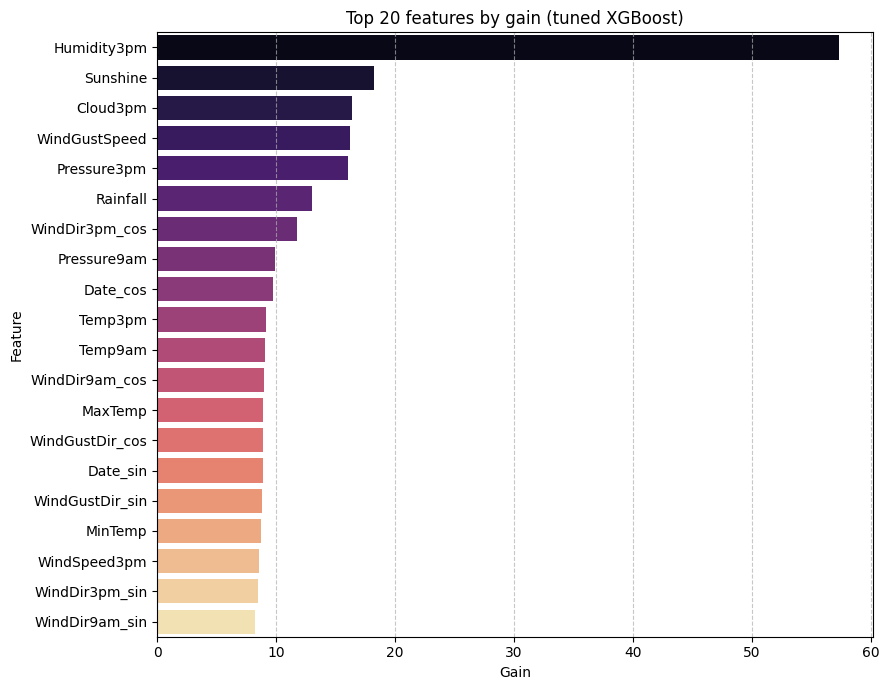

In [19]:
log_section('9. Feature importance & SHAP attribution')

# Gain-based importance from the tuned model.
booster = best_model.get_booster()
gain = booster.get_score(importance_type='gain')
imp_df = pd.DataFrame({
    'Feature': list(gain.keys()),
    'Gain': list(gain.values()),
}).sort_values('Gain', ascending=False).reset_index(drop=True)

print('Feature importance by gain (top 20):')
print(imp_df.head(20).to_string(index=False, float_format='%.2f'))

fig = plt.figure(figsize=(9, 7))
sns.barplot(data=imp_df.head(20), x='Gain', y='Feature',
            hue='Feature', palette='magma', legend=False)
plt.title('Top 20 features by gain (tuned XGBoost)')
plt.xlabel('Gain'); plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
save_fig('05_feature_importance_gain', fig)
plt.show()

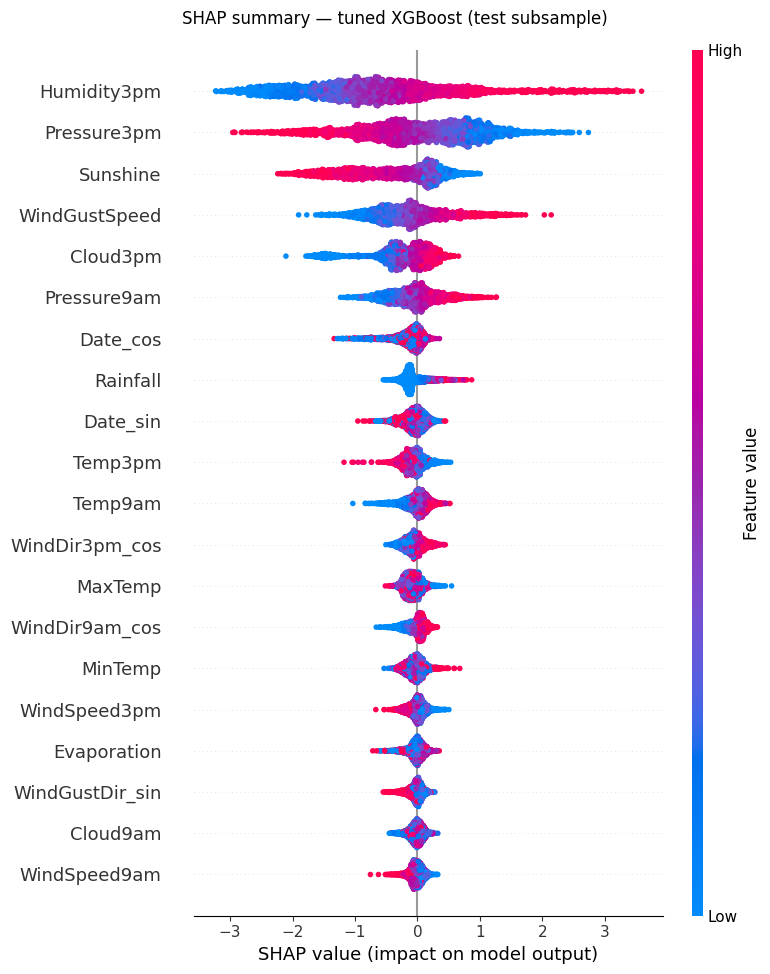

In [20]:
# SHAP summary (beeswarm). Subsample the test set for tractability.
# TreeExplainer uses the booster's GPU predictor when device="cuda", so this is fast.
if HAS_SHAP:
    try:
        n_shap = min(3000, X_test.shape[0])
        X_shap = X_test.sample(n=n_shap, random_state=RANDOM_STATE)
        explainer = shap.TreeExplainer(best_model)
        shap_values = explainer.shap_values(X_shap)

        plt.figure()
        shap.summary_plot(shap_values, X_shap, show=False)
        fig = plt.gcf()
        fig.suptitle('SHAP summary — tuned XGBoost (test subsample)', y=1.02)
        save_fig('06_shap_summary', fig)
        plt.show()

        mean_abs = pd.DataFrame({
            'Feature': X_shap.columns,
            'mean_abs_SHAP': np.abs(shap_values).mean(axis=0),
        }).sort_values('mean_abs_SHAP', ascending=False)
        print('\nMean |SHAP| ranking (top 15):')
        print(mean_abs.head(15).to_string(index=False, float_format='%.4f'))
    except Exception as e:
        print(f'SHAP computation failed ({type(e).__name__}: {e}); skipping.')
else:
    print('SHAP not installed — section limited to gain-based importance above.')

## 10. Calibration analysis

Boosting is typically miscalibrated out of the box. The LR recalibration machinery is
reused unchanged: reliability diagram, Brier, ECE, and post-hoc isotonic / Platt maps fit
on a chronological 85/15 refit-calibration split of the training period.

In [21]:
log_section('10. Calibration analysis')

def expected_calibration_error(y_true, y_prob, n_bins=10):
    bin_edges = np.linspace(0, 1, n_bins + 1)
    bin_idx = np.digitize(y_prob, bin_edges[1:-1])
    ece = 0.0
    n = len(y_true)
    for b in range(n_bins):
        mask = bin_idx == b
        if mask.sum() > 0:
            acc = y_true[mask].mean()
            conf = y_prob[mask].mean()
            ece += (mask.sum() / n) * abs(acc - conf)
    return ece

probs = {
    'baseline (no reweight)': y_proba_baseline,
    'tuned (best_model)':     y_proba_tuned,
}

calib_metrics = []
for name, p in probs.items():
    calib_metrics.append({
        'model':  name,
        'Brier':  brier_score_loss(y_test_i, p),
        'logloss': log_loss(y_test_i, np.clip(p, 1e-9, 1 - 1e-9)),
        'ECE_10': expected_calibration_error(y_test_i.values, p, n_bins=10),
        'mean_pred': float(np.mean(p)),
        'empirical_rate': float(y_test_i.mean()),
    })
calib_table = pd.DataFrame(calib_metrics).round(4)
print('\nCalibration metrics:')
print(calib_table.to_string(index=False))

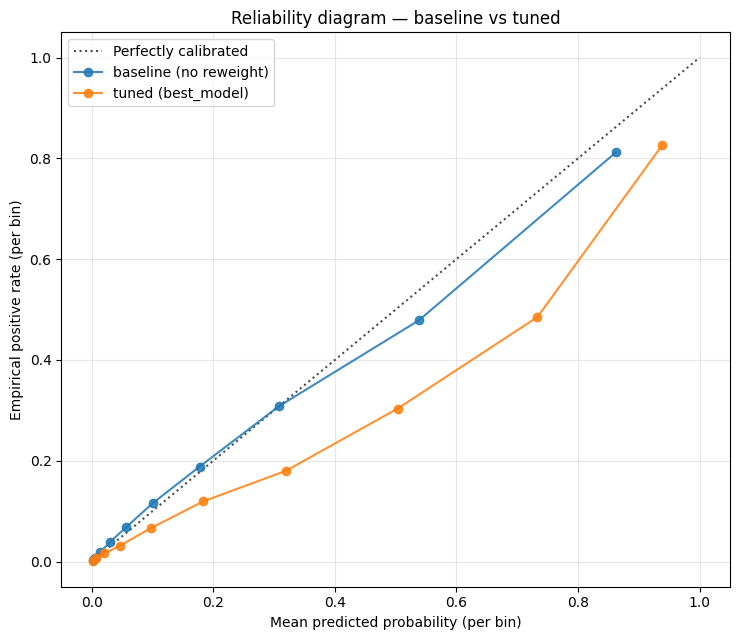

In [22]:
fig, ax = plt.subplots(figsize=(7.5, 6.5))
ax.plot([0, 1], [0, 1], 'k:', label='Perfectly calibrated', alpha=0.7)
for name, p in probs.items():
    prob_true, prob_pred = calibration_curve(y_test_i, p, n_bins=10, strategy='quantile')
    ax.plot(prob_pred, prob_true, 'o-', label=name, alpha=0.85)
ax.set_xlabel('Mean predicted probability (per bin)')
ax.set_ylabel('Empirical positive rate (per bin)')
ax.set_title('Reliability diagram — baseline vs tuned')
ax.legend(loc='upper left'); ax.grid(alpha=0.3)
plt.tight_layout()
save_fig('07_reliability_diagram', fig)
plt.show()

In [23]:
# Post-hoc recalibration: chronological 85/15 (refit, calibrate) split of the train period.
n_train = len(X_train)
calib_split = int(n_train * 0.85)
X_refit = X_train.iloc[:calib_split]
y_refit = y_train_i.iloc[:calib_split]
X_calib = X_train.iloc[calib_split:]
y_calib = y_train_i.iloc[calib_split:]

refit_model = XGBClassifier(**best_model.get_params())
refit_model.fit(X_refit, y_refit)

def make_calibrated(model, method, Xc, yc):
    """Calibrate a prefit model, handling both modern (FrozenEstimator) and
    legacy (cv='prefit') scikit-learn APIs."""
    try:
        from sklearn.frozen import FrozenEstimator
        cc = CalibratedClassifierCV(FrozenEstimator(model), method=method)
        cc.fit(Xc, yc)
        return cc
    except Exception:
        cc = CalibratedClassifierCV(model, method=method, cv='prefit')
        cc.fit(Xc, yc)
        return cc

calib_iso = make_calibrated(refit_model, 'isotonic', X_calib, y_calib)
calib_sig = make_calibrated(refit_model, 'sigmoid', X_calib, y_calib)

y_proba_iso = calib_iso.predict_proba(X_test)[:, 1]
y_proba_sig = calib_sig.predict_proba(X_test)[:, 1]

rows = []
for name, p in [('refit (uncalibrated)', refit_model.predict_proba(X_test)[:, 1]),
                ('isotonic recalibrated', y_proba_iso),
                ('sigmoid (Platt) recalibrated', y_proba_sig)]:
    rows.append({
        'method': name,
        'Brier':  brier_score_loss(y_test_i, p),
        'logloss': log_loss(y_test_i, np.clip(p, 1e-9, 1 - 1e-9)),
        'ECE_10': expected_calibration_error(y_test_i.values, p, n_bins=10),
        'mean_pred': float(np.mean(p)),
        'ROC_AUC': roc_auc_score(y_test_i, p),
    })
recalib_table = pd.DataFrame(rows).round(4)
print('\nPost-hoc recalibration metrics:')
print(recalib_table.to_string(index=False))

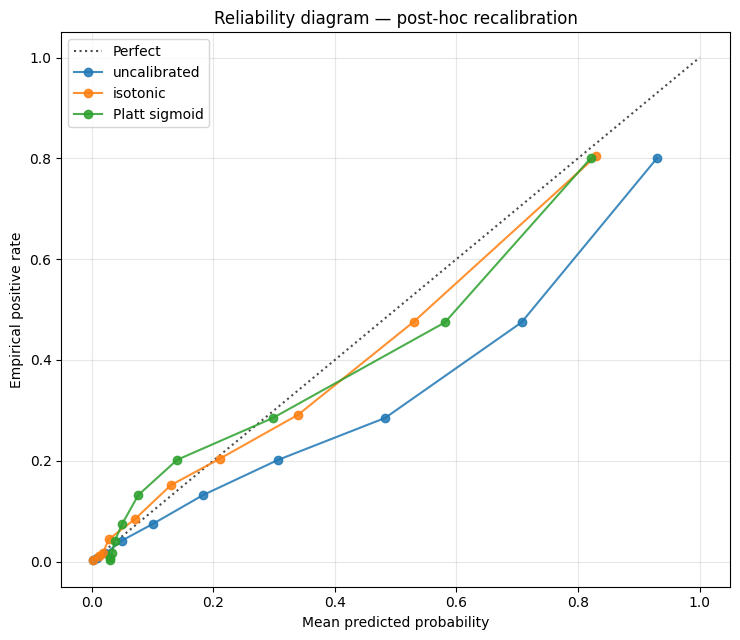

In [24]:
fig, ax = plt.subplots(figsize=(7.5, 6.5))
ax.plot([0, 1], [0, 1], 'k:', alpha=0.7, label='Perfect')
for name, p in [('uncalibrated', refit_model.predict_proba(X_test)[:, 1]),
                ('isotonic', y_proba_iso),
                ('Platt sigmoid', y_proba_sig)]:
    prob_true, prob_pred = calibration_curve(y_test_i, p, n_bins=10, strategy='quantile')
    ax.plot(prob_pred, prob_true, 'o-', label=name, alpha=0.85)
ax.set_xlabel('Mean predicted probability')
ax.set_ylabel('Empirical positive rate')
ax.set_title('Reliability diagram — post-hoc recalibration')
ax.legend(loc='upper left'); ax.grid(alpha=0.3)
plt.tight_layout()
save_fig('08_recalibration_reliability_diagram', fig)
plt.show()

## 11. Final evaluation curves

ROC and PR curves on the chronological test set, plus a `TimeSeriesSplit` learning curve to
check whether XGBoost has capacity headroom over the linear plateau (CV F1 ≈ 0.61).

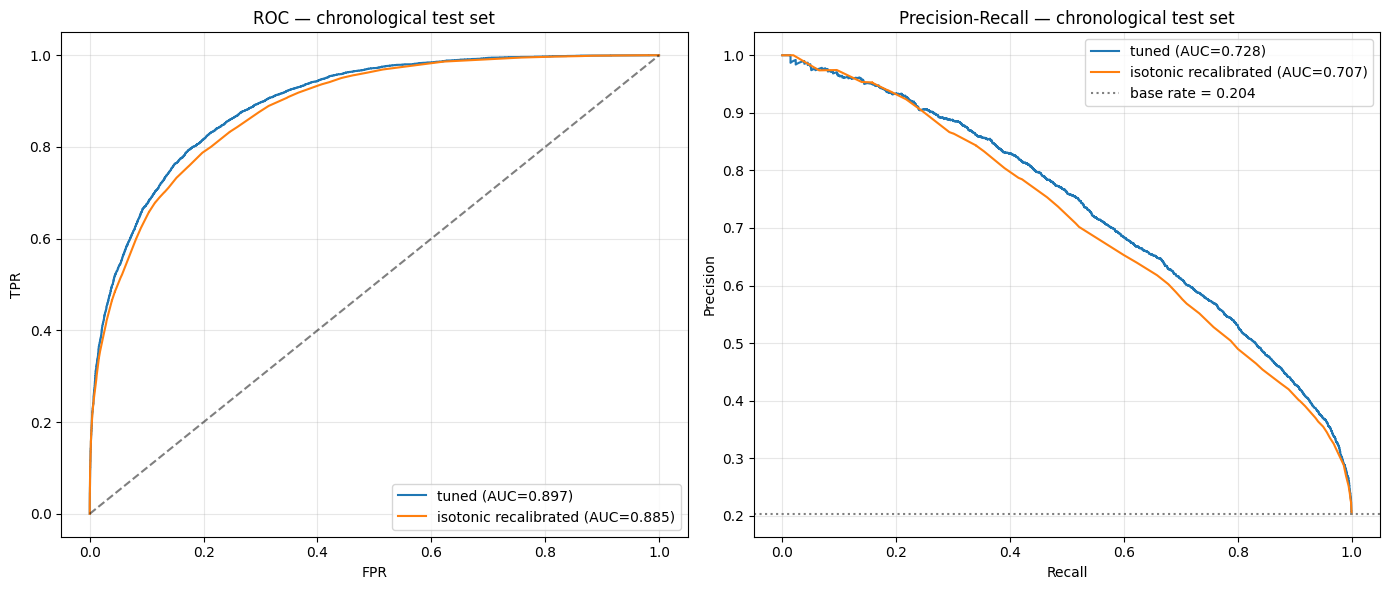

In [25]:
log_section('11. Final evaluation curves')

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

roc_aucs = {}
for name, p in [('tuned', y_proba_tuned),
                ('isotonic recalibrated', y_proba_iso)]:
    fpr, tpr, _ = roc_curve(y_test_i, p)
    auc_v = roc_auc_score(y_test_i, p)
    roc_aucs[name] = auc_v
    axes[0].plot(fpr, tpr, label=f'{name} (AUC={auc_v:.3f})')
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[0].set_xlabel('FPR'); axes[0].set_ylabel('TPR')
axes[0].set_title('ROC — chronological test set')
axes[0].legend(loc='lower right'); axes[0].grid(alpha=0.3)

base_rate = float(y_test_i.mean())
pr_aucs = {}
for name, p in [('tuned', y_proba_tuned),
                ('isotonic recalibrated', y_proba_iso)]:
    pr, rc, _ = precision_recall_curve(y_test_i, p)
    pr_auc = auc(rc, pr)
    pr_aucs[name] = pr_auc
    axes[1].plot(rc, pr, label=f'{name} (AUC={pr_auc:.3f})')
axes[1].axhline(base_rate, color='gray', linestyle=':', label=f'base rate = {base_rate:.3f}')
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall — chronological test set')
axes[1].legend(loc='upper right'); axes[1].grid(alpha=0.3)
plt.tight_layout()
save_fig('09_roc_pr_curves', fig)
plt.show()

print('\nROC-AUC by source:')
for name, v in roc_aucs.items():
    print(f'  {name:30s} {v:.4f}')
print('PR-AUC by source:')
for name, v in pr_aucs.items():
    print(f'  {name:30s} {v:.4f}')
print(f'Base rate (positive class fraction in test set): {base_rate:.4f}')

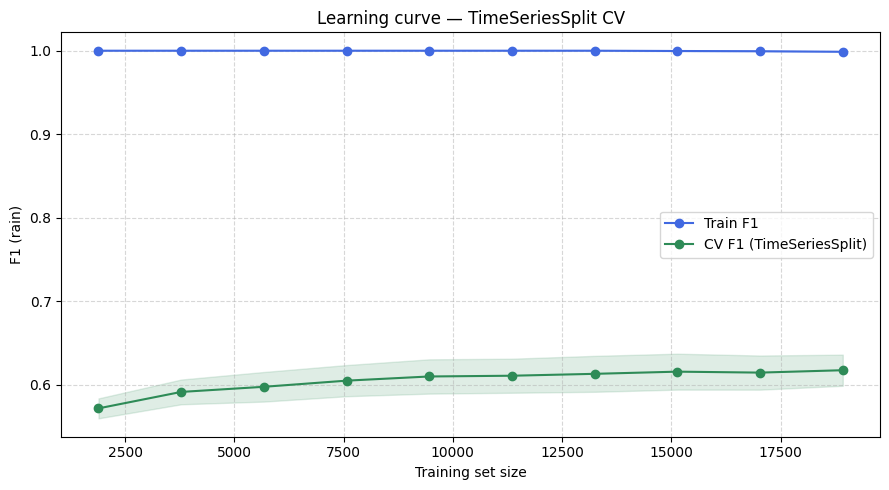

In [26]:
estimator = XGBClassifier(**best_model.get_params())
train_sizes, train_scores, val_scores = learning_curve(
    estimator, X_train, y_train_i,
    cv=ts_cv, scoring='f1', n_jobs=SEARCH_N_JOBS,
    train_sizes=np.linspace(0.1, 1.0, 10),
)
tr_m, tr_s = train_scores.mean(1), train_scores.std(1)
vl_m, vl_s = val_scores.mean(1), val_scores.std(1)

print('\nLearning curve — train and CV F1 by training set size:')
lc_df = pd.DataFrame({
    'train_size': train_sizes,
    'train_F1_mean': tr_m, 'train_F1_std': tr_s,
    'cv_F1_mean': vl_m, 'cv_F1_std': vl_s,
})
print(lc_df.to_string(index=False, float_format='%.4f'))

fig = plt.figure(figsize=(9, 5))
plt.plot(train_sizes, tr_m, 'o-', color='royalblue', label='Train F1')
plt.fill_between(train_sizes, tr_m - tr_s, tr_m + tr_s, alpha=0.15, color='royalblue')
plt.plot(train_sizes, vl_m, 'o-', color='seagreen', label='CV F1 (TimeSeriesSplit)')
plt.fill_between(train_sizes, vl_m - vl_s, vl_m + vl_s, alpha=0.15, color='seagreen')
plt.xlabel('Training set size'); plt.ylabel('F1 (rain)')
plt.title('Learning curve — TimeSeriesSplit CV')
plt.legend(); plt.grid(linestyle='--', alpha=0.5)
plt.tight_layout()
save_fig('10_learning_curve', fig)
plt.show()

## Finalization

Restores stdout, closes the log, lists the artifacts, and (on Colab) zips
`XGB_result.txt` + `figures/` and triggers a browser download.

In [27]:
log_section('Finalization')

print(f'Results file: {_XGB_RESULT_PATH}')
fig_files = sorted(f for f in os.listdir('figures') if f.lower().endswith('.png'))
print(f'Figures saved ({len(fig_files)}):')
for f in fig_files:
    print(f'  figures/{f}')

# Restore stdout and close log file
sys.stdout = _ORIG_STDOUT
_XGB_RESULT_FILE.close()

# Bundle artifacts into a zip for download.
ZIP_PATH = 'XGBoost_artifacts.zip'
with zipfile.ZipFile(ZIP_PATH, 'w', zipfile.ZIP_DEFLATED) as zf:
    zf.write(_XGB_RESULT_PATH)
    for f in fig_files:
        zf.write(f'figures/{f}')
print(f'Bundled artifacts into {ZIP_PATH}')

# On Colab, trigger a browser download.
if IN_COLAB:
    from google.colab import files
    files.download(ZIP_PATH)

print(f'\nDone. See {_XGB_RESULT_PATH} and figures/ for outputs.')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>